## PFP+ cells as a readout delivery dose
 
The project models how a binary reporter (RFP⁺ or not) responds to delivery dose, and asks how much that readout can reveal about differences in delivery. It has four parts that build on each other:
 
1. **Model:** a single-hit Poisson model links dose to the fraction of RFP⁺ cells.
2. **Simulate:** Monte Carlo generates synthetic data from the model, so its behaviour can be checked without relying only on algebra.
3. **Fit:** maximum likelihood estimates the model parameter from the data.
4. **Quantify uncertainty:** the fitted parameter gets an error bar, and the model can be compared with alternatives.
Together these form a *forward/backward* loop. Going forward, you start from a parameter value and simulate data. Going backward, you start from data and estimate the parameter. If the two directions agree, both the code and the reasoning are working.
 
---


## 1. The model
### The single-hit step
 
The number of copies Z delivered to a cell is assumed to follow a **Poisson distribution**. This is the standard model for sparse, independent events. Its mean is λ = kD, where D is the dose and k is a delivery constant.
 
A cell turns RFP⁺ if it receives **at least one** copy. From the Poisson probability of receiving zero copies:
 
$$P(Z = 0) = e^{-\lambda} \quad\Longrightarrow\quad P(\text{RFP}^+) = P(Z \ge 1) = 1 - e^{-kD}$$
 
This one line is the whole model. Two consequences follow from it:
 
- **Saturation is built into the model, not fitted.** As dose rises, the RFP⁺ fraction approaches 1. A cell that received five copies looks identical to one that received a single copy, because the reporter is binary and recombination is irreversible. The plateau therefore comes from the measurement itself, not from a limit on delivery.
- **Sensitivity falls with dose.** The slope is $dP/d\lambda = e^{-\lambda}$, so the readout's ability to tell two delivery levels apart decays *exponentially* with dose. At high dose, large real differences in delivery produce almost no change in the RFP⁺ fraction. Making this limitation explicit is the project's main contribution.
---

### Random numbers
 
A linear congruential generator produces a deterministic stream of uniform numbers on [0, 1). The same seed always gives the same stream, so every simulation in the project can be reproduced exactly. Before using the generator, check that its output stays in range, has a mean near 0.5, and fills each part of the interval evenly.
 
### From random numbers to cell outcomes
 
A uniform number becomes an outcome by splitting [0, 1) into slices whose lengths equal the outcome probabilities. Each cell has two outcomes, so there are two slices:
 
- if r < e^(−λ), the cell received no copies and is **RFP⁻**
- otherwise, it is **RFP⁺**
The same idea extends to drawing whole Poisson counts. Instead of simulating each event, step up the cumulative distribution until it passes r. This is the inverse-transform method.
 
### Event-by-event vs. drawing counts
 
There are two ways to simulate data:
 
1. **Event by event:** decide each cell's outcome individually. This is the most literal copy of the mechanism.
2. **Draw counts directly:** sample the total number of RFP⁺ cells from its distribution in one step.
In many problems the event-by-event route is far too slow. The course example would have taken roughly 36 hours. In this project it is cheap enough to keep, so both routes can be run and shown to agree. That agreement is a strong check that the simulation is correct.
 
---

In [3]:
import math
import matplotlib.pyplot as plt

# Constants for the LCG used in the course
A_LCG = 1664525
C_LCG = 1013904223
M_LCG = 2 ** 32

# LCG step
def lcg(state, a=A_LCG, c=C_LCG, m=M_LCG):
    return (a * state + c) % m

# Turning the integer sequence into number between 0 and 1
def uniforms(n, seed):
    """A list of n numbers on [0, 1): the generator run n times from the seed, each state divided by m."""
    if not isinstance(n, int) or isinstance(n, bool) or n < 0:
        raise ValueError("n must be a non-negative integer") # reject invalid size
    draws = [0.0] * n
    state = seed
    for i in range(n):
        state = lcg(state, A_LCG, C_LCG, M_LCG)
        draws[i] = state / M_LCG
    return draws


# Evaluating the single-hit probability for a dose and rate.
def p_model(k, dose):
    """Analytical probability that a cell is RFP+ at dose, for rate k."""
    if not math.isfinite(k) or k < 0: # checks for a negative delivery rate or dose outside
        raise ValueError("k must be a finite, non-negative number")
    if not math.isfinite(dose) or dose < 0:
        raise ValueError("dose must be a finite, non-negative number") # 1 - exp(-x) is evaluated as -expm1(-x) for better small-x precision.
    return -math.expm1(-k * dose)


# Convert a uniform number into a Poisson-distributed copy count.
def poisson_draw(lam, r):
    """Draw a Poisson count by inverse CDF from one uniform r in [0, 1)."""
    if not math.isfinite(lam) or lam < 0: # the Poisson mean must be finite and non-negative
        raise ValueError("lam must be a finite, non-negative number")
    if lam > 700: # at extreme means, exp(-lam) underflows and the CDF walk is unsuitable
        raise ValueError("inverse-CDF sampling requires lam <= 700")
    if not math.isfinite(r) or r < 0 or r >= 1:
        raise ValueError("r must be in [0, 1)") # inverse-CDF sampling requires a draw in the half-open interval [0, 1)

    # Begin the cumulative distribution at the probability of zero copies.
    probability = math.exp(-lam)  # P(Z = 0)
    cumulative = probability
    count = 0 # count is the number of copies associated with the current CDF
    # Keep adding probability mass until this uniform draw lands in the CDF.
    while r >= cumulative:
        count += 1
        probability *= lam / count # recurrence: P(Z=count) = P(Z=count-1) * lam/count.
        cumulative += probability
        if probability == 0.0: # if floating-point arithmetic loses all probability mass, report the failure.
            raise ArithmeticError("Poisson CDF stopped increasing before it covered r")
    # The current count is the sampled number of copies.
    return count

# Per-cell loop
def simulate(k, dose, n_cells=10000, seed=1):
    """Simulate cells by drawing Poisson copy counts; return the RFP+ fraction."""  
    lam = k * dose # poisson mean coppies per cell equals delivery rate times dose 
    draws = uniforms(n_cells, seed) # one number per cell
    positive = 0
    for r in draws: # convert each draw into a poisson copy count for one cell 
        copies = poisson_draw(lam, r)
        if copies >= 1:
            positive += 1
    return positive / n_cells # convert to a fraction

# Faster equivalent simulation: sample the reporter's two outcomes directly.
def simulate_binary(k, dose, n_cells=10000, seed=1):
    """Simulate the equivalent two-outcome RFP-negative/RFP-positive rule."""
    # Validate k and dose and find the probability that a cell gets zero copies.
    p_model(k, dose)
    probability_zero = math.exp(-k * dose) # use the same generator and seed as the full simulation for a fair comparison.
    draws = uniforms(n_cells, seed)
    positive = 0
    for r in draws:
        if r >= probability_zero:
            positive += 1
    return positive / n_cells

### Reproductibility and simulation check
 
 The full route samples a Poisson copy count for each cell. The shortcut samples the same cell's binary reporter state directly. With the same uniform numbers, these routes should agree exactly because $Z=0$ occupies the interval $[0,e^{-kD})$.

In [4]:
test_seed = 2026
test_k = 2.3e-3
test_dose = 100
test_cells = 10000

assert uniforms(5, test_seed) == uniforms(5, test_seed)
assert uniforms(5, test_seed) != uniforms(5, test_seed + 1)
assert all(0 <= r < 1 for r in uniforms(1000, test_seed))

full_simulation = simulate(test_k, test_dose, test_cells, test_seed)
binary_simulation = simulate_binary(test_k, test_dose, test_cells, test_seed)
expected_fraction = p_model(test_k, test_dose)

assert full_simulation == binary_simulation
assert abs(full_simulation - expected_fraction) < 0.01
print(f"seed={test_seed}, cells={test_cells}")
print(f"formula={expected_fraction:.4f}, Poisson simulation={full_simulation:.4f}, binary simulation={binary_simulation:.4f}")

seed=2026, cells=10000
formula=0.2055, Poisson simulation=0.2036, binary simulation=0.2036


## 3. Fitting the model: the maximum-likelihood idea
 
### The idea
 
Maximum likelihood chooses the value of k under which the observed data were most probable. The model gives the probability of the data for any candidate k. Read the other way round, with the data held fixed and k varied, the same expression becomes the **likelihood**. The likelihood is a score for candidate values of k. It is not a probability distribution over k.
 
For independent observations, the likelihood is the product of the individual probabilities. In practice, you minimise the **negative log-likelihood** (NLL) instead:
 
$$\mathrm{NLL}(k) = -\sum_i \ln p(x_i \mid k), \qquad \hat k = \arg\min_k \mathrm{NLL}(k)$$
 
Taking logs turns a product that underflows to zero into a sum that stays finite. The best k does not change, because the logarithm preserves the order of values. The estimate is the *position* of the minimum, not the NLL value at that point.
 
### Finding the minimum
 
A **grid sweep** scores many candidate values of k and keeps the best. In the real-data analysis below, the grid sweep minimizes the sum of squared differences between the digitized fractions and model predictions; it does not calculate the NLL above. Thus, maximum likelihood and NLL are introduced as general fitting concepts, while the reported real-data rates are squared-error point estimates. The likelihood-based uncertainty methods below are not computed for these fits.
 
### The noise model is part of the fit
 
Every fitting score assumes a model of how the data scatter around the curve. For example, least squares is maximum likelihood under constant normal noise. That assumption suits proportions poorly, because they are bounded between 0 and 1 and their spread depends on their value. Basing the likelihood on how the counts actually arise keeps the fit consistent with the model. If each measurement is a number of RFP⁺ cells out of a known total, this is a binomial likelihood. Fitting a distribution always asserts a mechanism, so the choice should be stated and justified.
 
---

In [5]:
# Read the companion CSV; keep it in the same folder as this notebook
import csv
from pathlib import Path

csv_path = Path("rfp_dose_response.csv")

# DictReader turns each CSV row into a dictionary keyed by the header names
with csv_path.open(newline="", encoding="utf-8") as data_file:
    data_rows = list(csv.DictReader(data_file))

# Convert one panel's CSV rows into the numeric lists expected by score() and fit().
def panel_data(panel_name):
    panel_rows = [row for row in data_rows if row["panel"] == panel_name]
    doses = [float(row["dose_ng"]) for row in panel_rows]
    observed = [float(row["rfp_positive_fraction"]) for row in panel_rows]
    return doses, observed


# Fig 1G is the primary dataset: keep all four per-well values at every dose
REAL_DOSES, REAL_OBSERVED = panel_data("Fig 1G")
# These digitized measurements are exact plotted values, not text-censored bounds
REAL_CENSORED = [False] * len(REAL_DOSES)

# Fig S1g is fitted separately as the companion dataset
S1G_DOSES, S1G_OBSERVED = panel_data("Fig S1g")
S1G_CENSORED = [False] * len(S1G_DOSES)


def score(k, doses, obs, censored):
    """Sum squared errors over uncensored dose/fraction observations only."""
    total = 0.0
    n_firm = 0
    # Examine each replicate independently, repeated doses are valid observations
    for dose, observed, is_censored in zip(doses, obs, censored):
        if is_censored: # censored values are constraints, not exact measurements to fit as targets
            continue
        if not math.isfinite(observed) or observed < 0 or observed > 1:
            raise ValueError("uncensored observations must be finite fractions in [0, 1]")
        # Compare this measured fraction with the model's predicted fraction
        difference = observed - p_model(k, dose)
        # Squared residuals cannot cancel, so lower totals indicate closer predictions
        total += difference * difference
        n_firm += 1
    if n_firm == 0:
        raise ValueError("at least one uncensored observation is required")
    return total


def position_of_min(values):
    """Return the index of the smallest value in a non-empty list."""
    if len(values) == 0:
        raise ValueError("values must not be empty")
    best = 0
    for i in range(1, len(values)):
        if values[i] < values[best]:
            best = i
    return best


def fit(doses, obs, censored, grid):
    """Return the candidate k with the smallest score on the supplied grid."""
    if len(grid) == 0:
        raise ValueError("grid must contain at least one candidate")
    scores = [score(k, doses, obs, censored) for k in grid] # evaluate the same dataset for every candidate k in the grid
    return grid[position_of_min(scores)]


# Search k from 0.000001 to 0.020000 per ng, at 0.000001 increments.
k_grid = [0.000001 * i for i in range(1, 20001)]

# Fit the two panels separately so their rates can be compared without pooling.
k_hat = fit(REAL_DOSES, REAL_OBSERVED, REAL_CENSORED, k_grid)
k_hat_s1g = fit(S1G_DOSES, S1G_OBSERVED, S1G_CENSORED, k_grid)

# Show observed means by dose alongside the estimated rates for both panels.
for panel_name, doses, observed, estimate in [
    ("Fig 1G", REAL_DOSES, REAL_OBSERVED, k_hat),
    ("Fig S1g", S1G_DOSES, S1G_OBSERVED, k_hat_s1g),
]:
    unique_doses = sorted(set(doses))
    means = [
        sum(y for d, y in zip(doses, observed) if d == dose)
        / sum(1 for d in doses if d == dose)
        for dose in unique_doses
    ]
    predictions = [p_model(estimate, dose) for dose in unique_doses]
    print(f"{panel_name}: k_hat={estimate:.6f} per ng")
    print("  dose (ng):", unique_doses)
    print("  observed mean:", [round(value, 4) for value in means])
    print("  model:", [round(value, 4) for value in predictions])

print(f"S1g / Fig 1G fitted-rate ratio: {k_hat_s1g / k_hat:.2f}")

Fig 1G: k_hat=0.001917 per ng
  dose (ng): [0.0, 10.0, 100.0, 1000.0]
  observed mean: [0.0, 0.025, 0.1353, 0.8745]
  model: [0.0, 0.019, 0.1744, 0.853]
Fig S1g: k_hat=0.009189 per ng
  dose (ng): [16.0, 50.0, 150.0]
  observed mean: [0.206, 0.435, 0.667]
  model: [0.1367, 0.3684, 0.748]
S1g / Fig 1G fitted-rate ratio: 4.79


## Synthetic recovery check

This is a software check, not experimental data. Generate fractions at a known rate, fit them on a candidate grid, and confirm that the fit returns a nearby value. Because the fractions are simulated, a small difference from the generating rate is expected.

## Plot the fitted models and sensitivity

The two digitized datasets are plotted separately because they have different fitted rates. Fig 1G spans the saturation region; Fig S1g is the lower-dose companion. The sensitivity plot uses the primary Fig 1G fit.

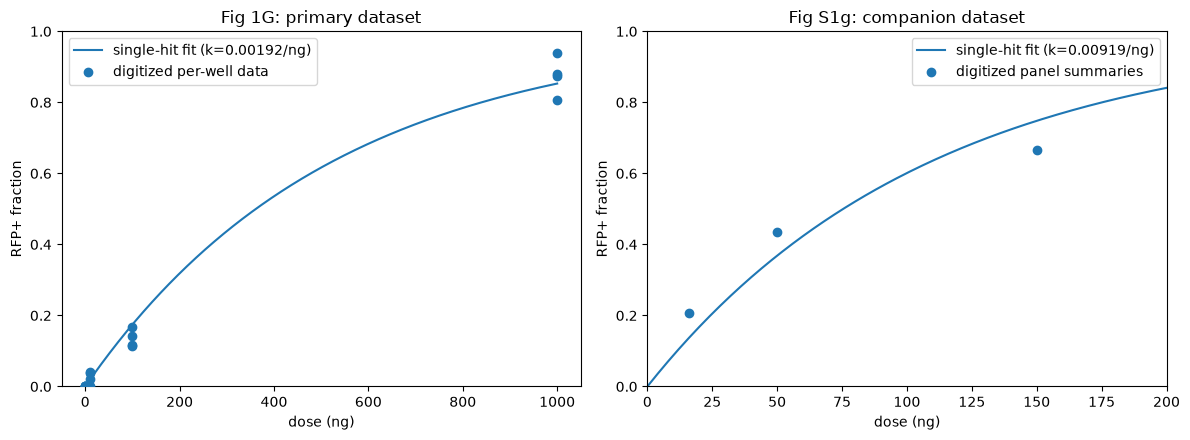

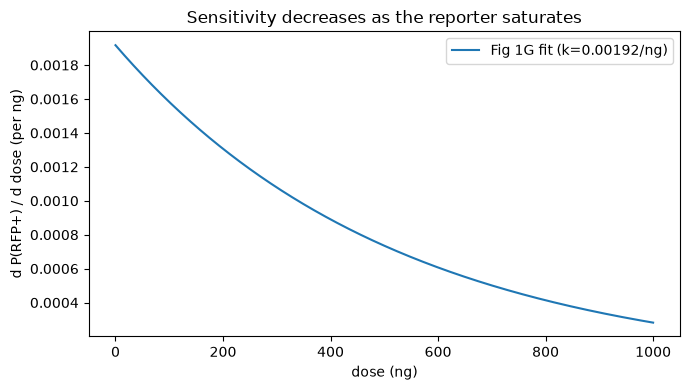

In [7]:
# Use a dense dose grid to draw smooth model curves from zero to 1000 ng.
dose_curve = [i for i in range(1001)]
# Predict the positive fraction at each dose using each panel's fitted rate.
fig1g_curve = [p_model(k_hat, dose) for dose in dose_curve]
s1g_curve = [p_model(k_hat_s1g, dose) for dose in dose_curve]
# Sensitivity is the dose derivative of the Fig 1G response: k * exp(-k*dose).
sensitivity_curve = [k_hat * math.exp(-k_hat * dose) for dose in dose_curve]

# Keep the primary and companion datasets in separate axes and do not pool them.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Show the Fig 1G fit together with all 16 digitized per-well measurements.
axes[0].plot(dose_curve, fig1g_curve, label=f"single-hit fit (k={k_hat:.5f}/ng)")
axes[0].scatter(REAL_DOSES, REAL_OBSERVED, label="digitized per-well data", zorder=3)
axes[0].set_title("Fig 1G: primary dataset")
axes[0].set_xlabel("dose (ng)")
axes[0].set_ylabel("RFP+ fraction")
axes[0].set_ylim(0, 1)
axes[0].legend()

# Show the S1g fit and its three supplied digitized summary values separately.
axes[1].plot(dose_curve, s1g_curve, label=f"single-hit fit (k={k_hat_s1g:.5f}/ng)")
axes[1].scatter(S1G_DOSES, S1G_OBSERVED, label="digitized panel summaries", zorder=3)
axes[1].set_xlim(0, 200)
axes[1].set_title("Fig S1g: companion dataset")
axes[1].set_xlabel("dose (ng)")
axes[1].set_ylabel("RFP+ fraction")
axes[1].set_ylim(0, 1)
axes[1].legend()

# Adjust spacing, then render both dose-response panels.
fig.tight_layout()
plt.show()

# Plot how the primary Fig 1G response loses sensitivity as it saturates.
plt.figure(figsize=(7, 4))
plt.plot(dose_curve, sensitivity_curve, label=f"Fig 1G fit (k={k_hat:.5f}/ng)")
plt.xlabel("dose (ng)")
plt.ylabel("d P(RFP+) / d dose (per ng)")
plt.title("Sensitivity decreases as the reporter saturates")
plt.legend()
plt.tight_layout()
plt.show()

### How to read the figures

In the two dose-response panels, the x-axis is the delivery dose in ng and the y-axis is the fraction of cells that are RFP-positive. The points show the digitized measurements; the smooth line is the fitted single-hit model, which predicts that the positive fraction rises with dose and approaches 1 as the reporter saturates. Fig 1G shows individual per-well measurements across a wide dose range, while Fig S1g shows three summary measurements at lower and intermediate doses. Each panel is fitted separately, so compare their trends without treating the points as one pooled dataset.

The sensitivity figure shows how much the predicted RFP-positive fraction changes for a small increase in dose, using the Fig 1G fit. Its y-axis is the change in fraction per ng. Sensitivity is highest at low doses and falls as the response saturates; near saturation, adding more dose produces little change in the positive fraction.

## 4. Uncertainty and model comparison
 
A fitted parameter is itself uncertain: repeating the experiment would give a different k̂. In this notebook, the plotted measurements are digitized fractions. Fig 1G contributes 16 per-well values (four at each of four doses), while Fig S1g contributes only three panel-level summary values. The code fits each panel by minimizing squared differences between these fractions and the model curve, so the reported k̂ values are point estimates, not maximum-likelihood estimates with error bars.
 
### Ways to get an error bar
 
| Method | Idea | Assumes |
|---|---|---|
| **Likelihood interval** | all k whose NLL is within ½ of the minimum (≈ ±1 SE) | the likelihood is correct |
| **Curvature** | a sharp NLL valley means a small error bar: σ = 1/√(NLL″) | the NLL is roughly parabolic near the minimum |
| **Bootstrap** | resample the data with replacement, refit, and use the spread of the refits | enough representative, independent data |
| **Bayesian credible interval** | posterior over k computed on a grid | a prior |
 
These are possible ways to quantify uncertainty when the data and a suitable sampling model are available; this notebook does not currently calculate any of these intervals for the digitized data. The plotted fractions do not include the numbers of RFP-positive and total cells behind each measurement, so a binomial likelihood interval or curvature-based standard error cannot be justified from the fractions alone. Fig S1g's three summary points also do not provide replicate-level variation. The displayed curves and fitted rates should therefore be read as descriptive fits, not as precise estimates with quantified uncertainty.
 
The methods also differ in what they mean. A Bayesian credible interval is a probability statement about k given the data and a prior; frequentist intervals describe the range of estimates compatible with repeated-sampling uncertainty under their assumptions. Neither interpretation is available here until the sampling information and an appropriate fit are supplied.
 
### Comparing models
 
- **AIC** = 2·NLL + 2·(number of parameters). Lower is better. An extra parameter must reduce the NLL by more than 1 to be worth keeping.
- **Deviance** compares the fit with a perfect "saturated" model. Deviance divided by the degrees of freedom should be about 1 for an adequate fit.
These tools can compare the single-hit model with alternatives, such as a model in which delivery varies between cells, when both models are fitted to the same observations using an appropriate likelihood. This notebook does not currently calculate AIC or deviance, so there is no model-comparison result to interpret. The difference between the two panels' fitted k values is not itself a model comparison: the panels are separate datasets fitted separately.
 
---

## Interpretation and limitations

### What the real data show

- **Fig 1G (primary, 16 per-well values):** the fitted rate is k̂ ≈ 0.00192 per ng, i.e. a dose of about 1/k̂ ≈ 520 ng gives a single-hit probability of 1 − e⁻¹ ≈ 63% RFP⁺ cells. The observed means rise from 0 (0 ng) to 0.025 (10 ng), 0.135 (100 ng) and 0.875 (1000 ng); the model predicts 0, 0.019, 0.174 and 0.853.
- **Fig S1g (companion, 3 summary values):** the fitted rate is k̂ ≈ 0.00919 per ng, about 4.8 times the Fig 1G rate. The observed fractions are 0.206 (16 ng), 0.435 (50 ng) and 0.667 (150 ng); the model predicts 0.137, 0.368 and 0.748.
- **Sensitivity (Fig 1G fit):** the response changes by about 0.0019 per ng near 0 ng, 0.0016 per ng at 100 ng, but only about 0.0003 per ng at 1000 ng. Around 1000 ng the readout is largely saturated, so a change in delivery there produces a much smaller change in the RFP⁺ fraction than the same change at low dose. Differences in delivery are therefore best resolved at low to intermediate doses and are hard to resolve near 1000 ng.

### Limitations

- **The two panels disagree and are not pooled.** A single k does not describe both, and the 4.8-fold difference in fitted rate is not explained by this analysis. It could reflect different experimental conditions or digitization differences; the data alone cannot say which.
- **The single-hit curve does not fit either panel closely.** For Fig 1G it overpredicts at 100 ng (0.174 vs 0.135) and slightly underpredicts at 1000 ng (0.853 vs 0.875). For Fig S1g the residuals change sign across the doses (underprediction at 16 and 50 ng, overprediction at 150 ng), so the data rise more slowly than the model curve at higher dose. With few points this is suggestive, not conclusive evidence against the single-hit model.
- **Little data constrain each fit.** Fig 1G has only four distinct doses, and Fig S1g has three points with no replicates, so each fit has very few degrees of freedom. The Fig 1G wells show visible spread (for example 0.807–0.938 at 1000 ng and 0.113–0.167 at 100 ng), which none of the reported k̂ values reflect.
- **No uncertainty or model comparison was computed.** The fits minimise squared error on digitized fractions. Cell counts per well are not available, so a binomial likelihood, likelihood interval, curvature error bar, AIC or deviance cannot be justified. The k̂ values are point estimates only, and no conclusion should rely on them being precise.
- **The data are digitized from published figures**, so they carry reading error in addition to experimental noise. Fig S1g values are panel summaries rather than per-well measurements, which is another reason not to treat the two panels as one dataset.
- **Censored observations** are not treated as exact targets; the digitized values here are treated as exact plotted values, not bounds.

### Limitations of the simulation checks

- The parameter `k` has inverse-dose units; `k * dose` is dimensionless.
- The seed and number of simulated cells are reported in the simulation check. Monte Carlo uncertainty decreases approximately as $1/\sqrt{n_{cells}}$.
- The full Poisson-count and binary simulations use the same random stream and must return the same fraction. This checks the code against the model, not the model against the real data.